# 召回、样本与检索
## Goal
把概念变成可检查的输入、运算、梯度与对照。

数据类型：**真实快照 + 机制练习**。本地教学参数不是生产默认值；机制实验不是原论文完整复现。

## Setup
每本首次从 Setup 起顺序运行，后面的格会复用前面的变量。之后只改一个参数，重跑对应格及下游格。不要把构造数据当作真实业务收益。

In [1]:
from pathlib import Path
import sys
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "reclab/models.py").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from reclab.data import Dataset
from reclab.paths import ARTIFACTS, PROCESSED, read_json

plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#182b2b", "text.color": "#182b2b",
    "axes.facecolor": "white", "figure.facecolor": "white",
    "grid.color": "#d4ddda", "axes.axisbelow": True})
dataset = Dataset()
print("Project:", PROJECT)
print("Dataset version:", dataset.manifest["dataset_version"])
print("Python:", sys.executable)
assert Path(sys.executable).parent == PROJECT / ".venv/bin", "请选择 Recommendation Lab 内核"

Project: /Users/lizuolin/local/recommendation-lab
Dataset version: 2772cab0aca8cb81
Python: /Users/lizuolin/local/recommendation-lab/.venv/bin/python


## Steps
讲义对应：02_Retrieval_01.pdf, 02_Retrieval_02.pdf, 02_Retrieval_03.pdf, 02_Retrieval_04.pdf, 02_Retrieval_05.pdf, 02_Retrieval_06.pdf, 02_Retrieval_07.pdf, 02_Retrieval_08.pdf, 02_Retrieval_09.pdf, 02_Retrieval_10.pdf, 02_Retrieval_11.pdf, 02_Retrieval_12.pdf

### UserCF 与 Swing
构造的可手算矩阵。Swing 是不加用户权重、每个无序用户对只计一次的教学变体。真实 ItemCF 见第 01 本。

**先预测：** 让两个用户额外共同喜欢十件物品，Swing 的单对贡献会变大还是变小？

In [2]:
from reclab.learning.retrieval import (binary_matrix, usercf, swing,
    MatrixFactorization, objective_losses, kmeans, partition_retrieval,
    beam_search, SideInfoEncoder, mask_fields)
import torch
from torch.nn import functional as F
torch.set_num_threads(4); torch.manual_seed(42)
matrix = binary_matrix([(0,0),(0,1),(0,2),(1,0),(1,1),(1,2),(2,0),(2,1),(3,2),(3,3)],4,4)
display(pd.DataFrame(matrix))
display(Code(inspect.getsource(swing),language="python"))
display(pd.DataFrame(swing(matrix)))
score, neighbors, similarity = usercf(matrix,0,2)
display(pd.DataFrame({"neighbor":neighbors,"cosine":similarity}))
assert np.allclose(swing(matrix),swing(matrix).T)

,0,1,2,3
0,1.0,1.0,1.0,0.0
1,1.0,1.0,1.0,0.0
2,1.0,1.0,0.0,0.0
3,0.0,0.0,1.0,1.0


def swing(matrix, alpha=1.0):
    """Unweighted Swing teaching variant. Each unordered user-pair is counted once."""
    if alpha <= 0:
        raise ValueError("alpha must be positive")
    histories = [set(np.flatnonzero(row)) for row in matrix]
    result = np.zeros((matrix.shape[1], matrix.shape[1]), dtype=float)
    for u, v in combinations(range(len(histories)), 2):
        common = histories[u] & histories[v]
        contribution = 1 / (alpha + len(common))
        for i, j in combinations(sorted(common), 2):
            result[i, j] += contribution
            result[j, i] += contribution
    return result

,0,1,2,3
0,0.000000,0.916667,0.25,0.0
1,0.916667,0.000000,0.25,0.0
2,0.250000,0.250000,0.00,0.0
3,0.000000,0.000000,0.00,0.0


,neighbor,cosine
0,1,1.000000
1,2,0.816497


### 真实训练交互上的矩阵分解 / BPR
只使用训练期。固定抽样负例可能包含潜在兴趣，训练 loss 下降不代表验证提升。

**先预测：** 把向量维度从 12 改成 4，参数量和拟合能力会怎样变化？

class MatrixFactorization(nn.Module):
    def __init__(self, n_users, n_items, dim=12):
        super().__init__()
        self.users = nn.Embedding(n_users, dim)
        self.items = nn.Embedding(n_items, dim)
        nn.init.normal_(self.users.weight, std=0.1)
        nn.init.normal_(self.items.weight, std=0.1)

    def forward(self, users, items):
        return (self.users(users) * self.items(items)).sum(-1)

    def bpr_loss(self, users, positive, negative):
        return F.softplus(-(self(users, positive) - self(users, negative))).mean()

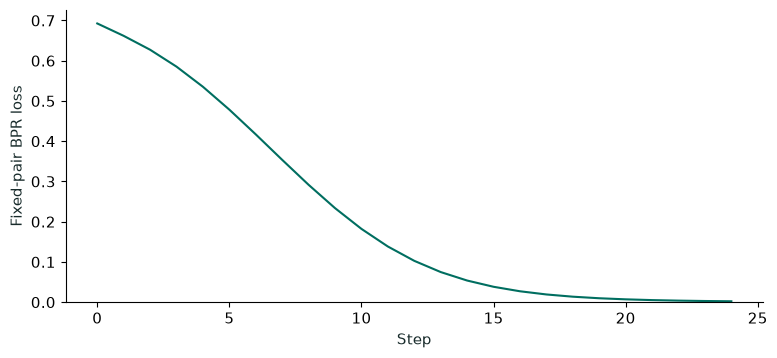

In [3]:
pairs = dataset.train[["user_idx","item_idx"]].drop_duplicates().head(1500).to_numpy()
u = torch.tensor(pairs[:,0],dtype=torch.long); p = torch.tensor(pairs[:,1],dtype=torch.long)
n = torch.randint(1,dataset.n_items,(len(pairs),))
n = torch.where(n==p, n%(dataset.n_items-1)+1, n)
mf = MatrixFactorization(dataset.n_users,dataset.n_items,dim=12)
opt = torch.optim.Adam(mf.parameters(),lr=.03); curve=[]
for step in range(25):
    opt.zero_grad(); loss=mf.bpr_loss(u,p,n)
    loss.backward(); opt.step(); curve.append(float(loss.detach()))
assert curve[-1] < curve[0]
display(Code(inspect.getsource(MatrixFactorization),language="python"))
plt.plot(curve,color="#006e60"); plt.xlabel("Step"); plt.ylabel("Fixed-pair BPR loss"); plt.ylim(bottom=0); plt.show()

### 三种损失、采样幂次与 LogQ
loss 尺度不可跨定义比较。讲义的 50/50 困难负例需要排序淘汰日志，现有数据没有该日志。

**先预测：** 指数改成 0 或 1，热门物品成为负例的概率会怎样变化？

In [4]:
p=torch.tensor([1.,2.,.5],requires_grad=True); n=torch.tensor([0.,1.,1.],requires_grad=True)
display(pd.Series({k:float(v.detach()) for k,v in objective_losses(p,n).items()}).to_frame("loss"))
counts=np.array([1.,10.,100.,1000.]); exponent=.75
sampling=counts**exponent; sampling/=sampling.sum()
display(pd.DataFrame({"count":counts,"uniform":.25,"power_sampling":sampling,"in_batch_prior":counts/counts.sum()}))
logits=torch.ones(1,4)
display(pd.DataFrame({"raw":logits.softmax(-1)[0].numpy(),
    "logq_corrected":(logits-torch.log(torch.tensor(sampling))[None,:]).softmax(-1)[0].numpy()}))

,loss
pointwise,0.705656
pairwise,0.533533
listwise,0.533533


,count,uniform,power_sampling,in_batch_prior
0,1.0,0.25,0.004628,0.000900
1,10.0,0.25,0.026025,0.009001
2,100.0,0.25,0.146352,0.090009
3,1000.0,0.25,0.822995,0.900090


,raw,logq_corrected
0,0.25,0.822995
1,0.25,0.146352
2,0.25,0.026025
3,0.25,0.004628


### 真实物品向量缓存与分区近似检索
和精确 Top20 的重合率只衡量索引误差，不是用户偏好 Recall。未部署大型 ANN 系统。

**先预测：** 为什么增加 probes 通常会增加代价？全量和增量更新时缓存版本应如何配对？

In [5]:
vectors=np.load(ARTIFACTS/"runs/baseline-history32/item_vectors.npy")[1:]
query=vectors[0]; exact=np.argsort(-(vectors@query))[:20]
centers, labels=kmeans(vectors,clusters=12,iterations=5)
rows=[]
for probes in [1,3,6,12]:
    found,count=partition_retrieval(vectors,query,centers,labels,probes=probes,k=20)
    rows.append({"probes":probes,"scored":count,"exact_top20_overlap":len(set(found)&set(exact))/20})
display(pd.DataFrame(rows))
assert rows[-1]["exact_top20_overlap"]==1.

,probes,scored,exact_top20_overlap
0,1,325,0.35
1,3,1122,1.00
2,6,2609,1.00
3,12,5000,1.00


### Deep Retrieval 的路径搜索环节
仅复现条件路径概率与 beam search，未实现神经路径学习和交替优化，不能称作完整 Deep Retrieval。

**先预测：** 局部概率最大，为什么不等于整条路径概率最大？

In [6]:
transition={():{"A":.6,"B":.4},("A",):{"x":.5,"y":.5},("B",):{"x":.99,"y":.01}}
display(Code(inspect.getsource(beam_search),language="python"))
display(pd.DataFrame([{"width":w,"best":beam_search(transition,width=w)[0][0],
    "probability":np.exp(beam_search(transition,width=w)[0][1])} for w in [1,2,4]]))
assert beam_search(transition,width=1)[0][0] != beam_search(transition,width=4)[0][0]

def beam_search(transition, depth=2, width=1):
    """Conditional path probabilities. No neural path/index learning is claimed."""
    beams = [((), 0.0)]
    for _ in range(depth):
        expanded = []
        for path, log_prob in beams:
            for node, probability in transition[path].items():
                expanded.append((path + (node,), log_prob + np.log(probability)))
        beams = sorted(expanded, key=lambda row: (-row[1], row[0]))[:width]
    return beams

,width,best,probability
0,1,"(A, x)",0.300
1,2,"(B, x)",0.396
2,4,"(B, x)",0.396


### 字段自监督与 Bloom 过滤
使用真实训练截止属性做 SSL 梯度诊断；没有将辅助任务接入正式双塔。Bloom 使用构造的整数 ID，不等同于真实曝光日志。

**先预测：** Bloom 存储翻倍会怎样？字段 Mask 和隐藏层 dropout 有什么区别？

In [7]:
cats={v:i+1 for i,v in enumerate(sorted({x["category"] for x in dataset.items}))}
ids=torch.arange(1,65); categories=torch.tensor([cats[x["category"]] for x in dataset.items[:64]])
encoder=SideInfoEncoder(dataset.n_items,len(cats)+1)
a=encoder(*mask_fields(ids,categories,.5)); b=encoder(*mask_fields(ids,categories,.5))
ssl=F.cross_entropy(a@b.T/.2,torch.arange(64)); ssl.backward()
assert torch.isfinite(ssl)
print("SSL mechanism loss:",float(ssl.detach()))
from reclab.learning.systems import BloomFilter
bloom=BloomFilter(bits=512,hashes=4)
for i in range(100):bloom.add(i)
assert all(bloom.contains(i) for i in range(100))
print("False positives on 5000 unseen IDs:",np.mean([bloom.contains(i) for i in range(100,5100)]))
print("Author/geo/social retrieval requires matching fields; see explicitly simulated social exercise in chapter 10.")

SSL mechanism loss: 3.8621013164520264
False positives on 5000 unseen IDs: 0.093
Author/geo/social retrieval requires matching fields; see explicitly simulated social exercise in chapter 10.


## Checks
所有断言和输出都可回溯到代码。它们验证算子、数据快照或机制，不是线上收益。

## Next Steps
先记录预测，只改一个变量，再运行对应实验格。需要查看辅助函数时，打开 reclab/learning/。